# <a href="https://girafe.ai/" target="_blank" rel="noopener noreferrer"><img src="https://raw.githubusercontent.com/girafe-ai/ml-course/7096a5df4cada5ee651be1e3215c2f7fb8a7e0bf/logo_margin.svg" alt="girafe-ai logo" width="150px" align="left"></a> YMLS Uzbekistan, ML Fundamentals, fall 2026 <a class="tocSkip">

# Week 1, seminar 1: the ML workflow

One small dataset (Wine), one simple model (kNN) and the whole loop from the lecture: problem, data, split, baseline, model, validation, test and an experiment log. Today the loop matters more than the model.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/girafe-ai/ml-course/blob/26f_ymls_uz/week0_01_intro_and_knn/week0_01_01_ml_workflow_and_baseline__completed.ipynb)

This week's [lecture slides](https://github.com/girafe-ai/ml-course/blob/26f_ymls_uz/week0_01_intro_and_knn/ml-basic_lect01_intro_knn.pdf) and [interactive pages](https://raw.githack.com/girafe-ai/ml-course/26f_ymls_uz/week0_01_intro_and_knn/interactive/index.html) (`interactive/index.html`) are in the same folder.

_YMLS Uzbekistan, ML Fundamentals, fall 2026_

_Completed version with solutions and outputs. The student version is `week0_01_01_ml_workflow_and_baseline.ipynb`._

## 0. Setup

In [1]:
import subprocess
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from sklearn.datasets import load_wine
from sklearn.dummy import DummyClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedGroupKFold,
    StratifiedKFold,
    cross_val_score,
    train_test_split,
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler


SEED = 42  # one seed for every split, fold and random generator

# Plot style: gray axes, colour only for data
INK, INK2, INK3, LINE = "#1D1D1F", "#6E6E73", "#86868B", "#D2D2D7"
ACCENT = "#0071E3"
CLASS_COLORS = ["#0071E3", "#FF9F0A", "#34C759"]  # classes 0, 1, 2
MARKERS = ["o", "s", "^"]  # every class also gets its own marker
SPLIT_COLORS = {"train": "#0071E3", "val": "#FF9F0A", "test": "#AF52DE"}
plt.rcParams.update(
    {
        "font.family": "sans-serif",
        "font.sans-serif": ["Helvetica Neue", "Arial", "DejaVu Sans"],
        "font.size": 13,
        "axes.edgecolor": LINE,
        "axes.linewidth": 0.8,
        "axes.labelcolor": INK2,
        "axes.titlecolor": INK,
        "axes.titlesize": 14,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.titlepad": 10,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": False,
        "axes.prop_cycle": plt.cycler(color=CLASS_COLORS + [SPLIT_COLORS["test"], INK3]),
        "xtick.color": INK3,
        "ytick.color": INK3,
        "xtick.labelsize": 11,
        "ytick.labelsize": 11,
        "xtick.major.size": 0,
        "ytick.major.size": 0,
        "legend.frameon": False,
        "legend.fontsize": 11,
        "lines.linewidth": 2.2,
        "lines.markersize": 6,
        "figure.facecolor": "white",
    }
)
BLUES = LinearSegmentedColormap.from_list("ymls_blue", ["#F5F5F7", ACCENT])

## 1. The problem

We have chemical analyses of 178 wines from one region of Italy, made from three cultivars (grape varieties). Given the 13 measurements of a new wine (alcohol, malic acid, ..., proline), predict its cultivar: class 0, 1 or 2.

This is supervised multiclass classification: we have objects with known answers and want a rule $a(x)$ that answers correctly on new objects. The terms from the lecture, in code:

| Term | Here | In code |
|---|---|---|
| object $x_i$ | one wine | a row of `X` |
| feature $x^{(j)}$ | one chemical measurement | a column of `X` |
| design matrix $X \in \mathbb{R}^{\ell \times d}$ | all wines × all measurements | `X`, a `pd.DataFrame` |
| target $y$ | the cultivar: 0, 1 or 2 | `y`, a `pd.Series` |
| model $a(x)$ | a rule from features to a class | an sklearn estimator: `fit`, `predict` |
| quality metric | share of correct answers (accuracy) | `accuracy_score(y_true, y_pred)` |

In [2]:
wine = load_wine(as_frame=True)  # bundled with scikit-learn, no download needed
X, y = wine.data, wine.target  # design matrix and target

X.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


**Exercise 1.1.** How many objects $\ell$ and features $d$ do we have?

In [3]:
ell, d = X.shape

assert (ell, d) == (178, 13), "X.shape is (number of objects, number of features)"
print(f"ell = {ell} objects, d = {d} features")

ell = 178 objects, d = 13 features


In this course the design matrix always has shape `(n_objects, n_features)`, one row per object.

Now the features. Look at the `std` column: `proline` varies by hundreds, `hue` by about 0.2. This will matter for kNN.

In [4]:
X.describe().T[["mean", "std", "min", "max"]].round(2)

,mean,std,min,max
alcohol,13.00,0.81,11.03,14.83
malic_acid,2.34,1.12,0.74,5.80
ash,2.37,0.27,1.36,3.23
alcalinity_of_ash,19.49,3.34,10.60,30.00
magnesium,99.74,14.28,70.00,162.00
total_phenols,2.30,0.63,0.98,3.88
flavanoids,2.03,1.00,0.34,5.08
nonflavanoid_phenols,0.36,0.12,0.13,0.66
proanthocyanins,1.59,0.57,0.41,3.58
color_intensity,5.06,2.32,1.28,13.00


**Exercise 1.2.** What share of the wines is in each class? A model that always predicts the most frequent class gets exactly that share right.

In [5]:
class_share = y.value_counts(normalize=True).sort_index()

assert class_share is not None, "Fill in class_share"
assert np.isclose(class_share.sum(), 1.0) and len(class_share) == 3
class_share.round(3).to_frame("share")

,share
target,
0,0.331
1,0.399
2,0.270


Class 1 is the largest, about 40%, so an accuracy of 0.4 is worth nothing on this data.

## 2. Train, validation and test

Split the data once, before anything else:

| Part | Share | Used for |
|---|---|---|
| train | 60% | the model learns its parameters (`fit`) |
| validation | 20% | comparing models and choosing hyperparameters such as `k` |
| test | 20% | one final estimate of quality on new data |

Use the test set once, at the very end. If you pick the model, `k` or the features by looking at test scores, the test set turns into a second validation set and its score is no longer honest.

`stratify=y` keeps the class proportions equal in all parts, and a fixed `random_state` makes the split reproducible.

In [6]:
# Step 1: hold out 20% of all data as the test set
X_trval, X_test, y_trval, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)

# Step 2: split the remaining 80% into train (60% of all) and validation (20% of all)
X_train, X_val, y_train, y_val = train_test_split(
    X_trval, y_trval, test_size=0.25, stratify=y_trval, random_state=SEED
)

In [7]:
assert X_train is not None, "Fill in the split in the cell above"
assert (len(X_train), len(X_val), len(X_test)) == (106, 36, 36), "Expected a 60/20/20 split"
assert not set(X_train.index) & set(X_val.index), "Train and validation must not overlap"
assert not set(X_trval.index) & set(X_test.index), "Train+val and test must not overlap"

parts = {"all": y, "train": y_train, "val": y_val, "test": y_test}
split_table = pd.DataFrame(
    {name: part.value_counts(normalize=True) for name, part in parts.items()}
).sort_index()
split_table.index = [f"class {label} share" for label in split_table.index]
split_table.loc["size"] = [len(part) for part in parts.values()]
split_table.round(2)

,all,train,val,test
class 0 share,0.33,0.33,0.33,0.33
class 1 share,0.40,0.41,0.39,0.39
class 2 share,0.27,0.26,0.28,0.28
size,178.00,106.00,36.00,36.00


## 3. Baseline first

A baseline is the simplest reasonable solution. Every real model must beat it; if it does not, the model is useless or there is a bug.

We try two baselines and collect their validation accuracies in `val_scores`: a constant that always predicts the most frequent training class (`DummyClassifier`), and a rule that cuts one feature into three intervals and gives each interval a class.

**Exercise 3.1.** Fit `DummyClassifier(strategy="most_frequent")` on train and compute its accuracy on validation.

In [8]:
val_scores = {}  # model name -> validation accuracy

dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
dummy_val_acc = accuracy_score(y_val, dummy.predict(X_val))

assert dummy_val_acc is not None, "Fill in dummy_val_acc"
assert 0.3 < dummy_val_acc < 0.5, "Did you compute accuracy on the validation set?"
val_scores["baseline: most frequent class"] = dummy_val_acc
print(f"most frequent class, val accuracy: {dummy_val_acc:.3f}")

most frequent class, val accuracy: 0.389


The threshold rule is also learned on train: sort the classes by the mean of the feature and put the two thresholds halfway between neighbouring class means.

In [9]:
def fit_threshold_rule(x, y):
    """Learn a 3-interval rule on one feature x. Returns (classes, thresholds)."""
    class_means = pd.Series(np.asarray(x)).groupby(np.asarray(y)).mean().sort_values()
    classes = class_means.index.to_numpy()  # classes ordered by the mean of x
    means = class_means.to_numpy()
    thresholds = (means[:-1] + means[1:]) / 2  # midpoints between neighbouring means
    return classes, thresholds


def predict_threshold_rule(x, classes, thresholds):
    # np.digitize returns the interval each value falls into: 0, 1 or 2
    return classes[np.digitize(np.asarray(x), thresholds)]


classes, thresholds = fit_threshold_rule(X_train["alcohol"], y_train)
print("classes from low to high alcohol:", classes, "| thresholds:", thresholds.round(2))

classes from low to high alcohol: [1 2 0] | thresholds: [12.71 13.43]


**Exercise 3.2.** Which single feature gives the best rule? Fit the rule on every feature and pick the feature with the best train accuracy. Validation is kept for comparing finished models.

In [10]:
train_acc_by_feature = {}  # feature name -> train accuracy of its rule
for feature in X.columns:
    classes, thresholds = fit_threshold_rule(X_train[feature], y_train)
    train_pred = predict_threshold_rule(X_train[feature], classes, thresholds)
    train_acc_by_feature[feature] = accuracy_score(y_train, train_pred)

best_feature = max(train_acc_by_feature, key=train_acc_by_feature.get)

best feature: flavanoids (train accuracy 0.783)
threshold rule, val accuracy: 0.750


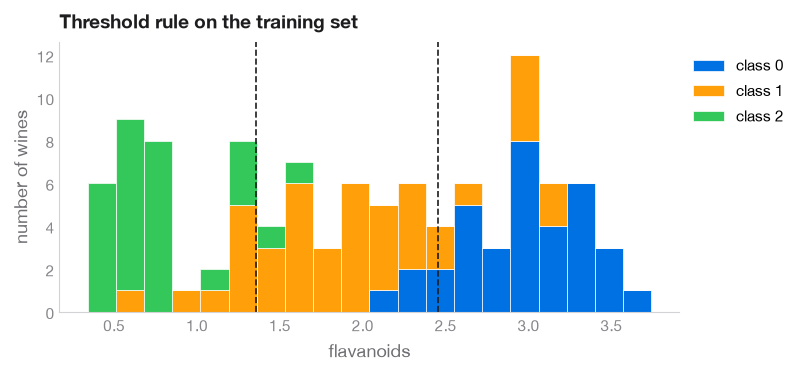

In [11]:
assert best_feature in X.columns, "Fill in the cell above"
classes, thresholds = fit_threshold_rule(X_train[best_feature], y_train)
val_pred = predict_threshold_rule(X_val[best_feature], classes, thresholds)
rule_val_acc = accuracy_score(y_val, val_pred)
val_scores[f"baseline: threshold rule on {best_feature}"] = rule_val_acc

print(f"best feature: {best_feature} (train accuracy {train_acc_by_feature[best_feature]:.3f})")
print(f"threshold rule, val accuracy: {rule_val_acc:.3f}")

fig, ax = plt.subplots(figsize=(8, 3.5))
bins = np.histogram_bin_edges(X_train[best_feature], bins=20)
values = [X_train.loc[y_train == label, best_feature] for label in range(3)]
labels = [f"class {label}" for label in range(3)]
ax.hist(values, bins=bins, stacked=True, color=CLASS_COLORS, label=labels, ec="white", lw=0.5)
for threshold in thresholds:
    ax.axvline(threshold, color=INK, ls="--", lw=1.2)
ax.set(xlabel=best_feature, ylabel="number of wines", title="Threshold rule on the training set")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

A rule on a single feature already nearly doubles the accuracy of the constant. kNN has to beat it.

## 4. kNN with and without scaling

kNN predicts the majority class among the `k` training objects closest to $x$, by Euclidean distance over all 13 features:

$$\rho(x, z) = \sqrt{\sum_{j=1}^{d} \left(x^{(j)} - z^{(j)}\right)^2}.$$

A feature in large units (`proline`, hundreds) outweighs features in small units (`hue`, around 1). The fix is to standardize every feature, $x^{(j)} \mapsto (x^{(j)} - \mu_j) / \sigma_j$, with $\mu_j, \sigma_j$ estimated on the training set only.

`make_pipeline(StandardScaler(), KNeighborsClassifier())` does this for you: `fit` estimates $\mu, \sigma$ on train and then fits kNN, and `predict` reuses the same $\mu, \sigma$. Fitting the scaler on the whole dataset before the split would be data leakage (section 5).

**Exercise 4.1.** Compute the validation accuracy of kNN with `k = 5` on raw features and with standardization.

In [12]:
knn_raw = KNeighborsClassifier(n_neighbors=5).fit(X_train, y_train)
knn_raw_val_acc = knn_raw.score(X_val, y_val)  # .score() of a classifier is accuracy

knn_scaled = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
knn_scaled.fit(X_train, y_train)
knn_scaled_val_acc = knn_scaled.score(X_val, y_val)

In [13]:
assert knn_raw_val_acc is not None and knn_scaled_val_acc is not None, "Fill in the cell above"
assert knn_scaled_val_acc > knn_raw_val_acc, "Scaling should help kNN on Wine"
val_scores["kNN, k=5, raw features"] = knn_raw_val_acc
val_scores["kNN, k=5, StandardScaler"] = knn_scaled_val_acc

pd.Series(val_scores, name="val accuracy").round(3).to_frame()

,val accuracy
baseline: most frequent class,0.389
baseline: threshold rule on flavanoids,0.750
"kNN, k=5, raw features",0.694
"kNN, k=5, StandardScaler",0.972


Without scaling, kNN loses even to the one-feature rule. With scaling, it is far ahead.

**Exercise 4.2.** Choose `k` on validation: compute the validation accuracy of both models for $k = 1, \dots, 30$.

In [14]:
ks = list(range(1, 31))
val_acc_raw, val_acc_scaled = [], []
for k in ks:
    raw = KNeighborsClassifier(n_neighbors=k).fit(X_train, y_train)
    scaled = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    scaled.fit(X_train, y_train)
    val_acc_raw.append(raw.score(X_val, y_val))
    val_acc_scaled.append(scaled.score(X_val, y_val))

best k on validation (scaled): 7, val accuracy 1.000


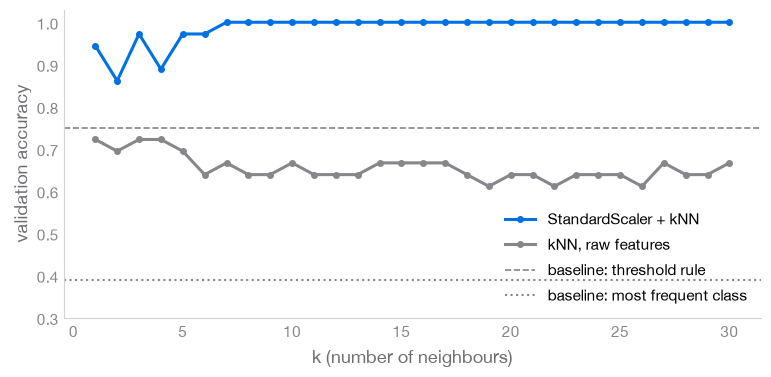

In [15]:
assert len(val_acc_scaled) == len(ks), "Fill in the loop above"
best_k_val = ks[int(np.argmax(val_acc_scaled))]
print(f"best k on validation (scaled): {best_k_val}, val accuracy {max(val_acc_scaled):.3f}")

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(ks, val_acc_scaled, "o-", ms=4, color=ACCENT, label="StandardScaler + kNN")
ax.plot(ks, val_acc_raw, "o-", ms=4, color=INK3, label="kNN, raw features")
ax.axhline(rule_val_acc, color=INK3, ls="--", lw=1.2, label="baseline: threshold rule")
ax.axhline(dummy_val_acc, color=INK3, ls=":", lw=1.5, label="baseline: most frequent class")
ax.set(xlabel="k (number of neighbours)", ylabel="validation accuracy", ylim=(0.3, 1.03))
ax.legend(loc="lower right")
plt.show()

With 36 validation objects one mistake costs 2.8% of accuracy, so many values of `k` tie on the scaled curve. One validation split gives a noisy estimate.

Cross-validation uses the data better. Merge train and validation (142 objects) and cut them into 5 folds. Train on 4 folds, evaluate on the fifth, repeat 5 times and average. The test set stays untouched.

In [16]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)  # reused below

**Exercise 4.3.** Compute the 5-fold cross-validation accuracy of the scaled kNN pipeline (`k = 5`) on `X_trval, y_trval`.

In [17]:
cv_scores = cross_val_score(
    make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    X_trval,
    y_trval,
    cv=cv,
    scoring="accuracy",
)

assert cv_scores is not None and len(cv_scores) == 5, "Fill in cv_scores"
print("accuracy on each fold:", cv_scores.round(3))
print(f"5-fold CV accuracy: {cv_scores.mean():.3f} ± {cv_scores.std():.3f}")

accuracy on each fold: [0.897 1.    0.964 0.929 0.964]
5-fold CV accuracy: 0.951 ± 0.035


**Exercise 4.4.** `GridSearchCV` cross-validates every combination of hyperparameters and keeps the best one. Inside a pipeline, parameters are named `<step name>__<parameter>`. Fit the grid below.

In [18]:
pipe = Pipeline([("scaler", StandardScaler()), ("knn", KNeighborsClassifier())])
param_grid = {
    "knn__n_neighbors": list(range(1, 41)),
    "knn__weights": ["uniform", "distance"],
}
grid = GridSearchCV(pipe, param_grid, cv=cv, scoring="accuracy")
grid = grid.fit(X_trval, y_trval)  # fit returns the fitted object itself

best params: {'knn__n_neighbors': 29, 'knn__weights': 'uniform'}
best 5-fold CV accuracy: 0.979


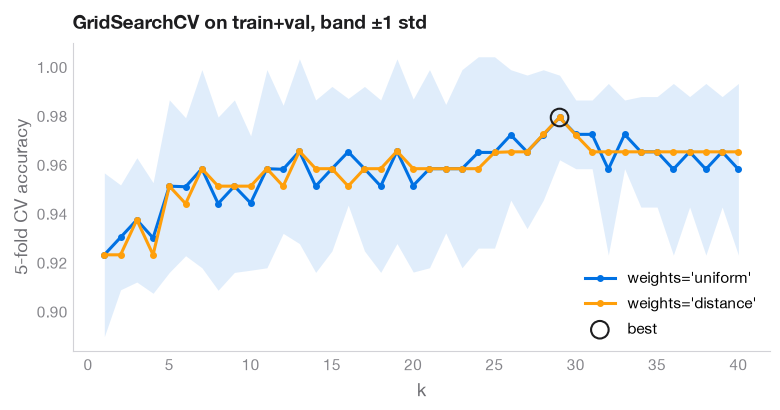

In [19]:
assert hasattr(grid, "best_params_"), "Fit grid in the cell above"
print("best params:", grid.best_params_)
print(f"best 5-fold CV accuracy: {grid.best_score_:.3f}")

results = pd.DataFrame(grid.cv_results_)
fig, ax = plt.subplots(figsize=(9, 4))
for weights, color in [("uniform", ACCENT), ("distance", SPLIT_COLORS["val"])]:
    part = results[results["param_knn__weights"] == weights]
    k_values = part["param_knn__n_neighbors"].astype(int)
    mean, std = part["mean_test_score"], part["std_test_score"]
    ax.plot(k_values, mean, "o-", ms=4, color=color, label=f"weights={weights!r}")
    if weights == "uniform":  # one band is enough: the two curves almost coincide
        ax.fill_between(k_values, mean - std, mean + std, color=color, alpha=0.12, lw=0)
ax.scatter(
    [grid.best_params_["knn__n_neighbors"]],
    [grid.best_score_],
    s=160,
    facecolor="none",
    edgecolor=INK,
    linewidth=1.5,
    zorder=5,
    label="best",
)
ax.set(xlabel="k", ylabel="5-fold CV accuracy", title="GridSearchCV on train+val, band ±1 std")
ax.legend(loc="lower right")
plt.show()

The band (±1 standard deviation over the folds) is wide: on 142 objects, most values of `k` above about 5 cannot be told apart. On data this small, do not read much into the third decimal.

## 5. Data leakage

Leakage means that information you will not have at prediction time gets into training or model selection. The model then looks better in the notebook than it will in production. Here are three cases, all checked with cross-validation on train+val. The test set stays untouched.

### 5.1 Scaler fitted before cross-validation

In [20]:
# Wrong: the scaler sees all 142 rows, including the rows of every validation fold
X_trval_scaled = StandardScaler().fit_transform(X_trval)
leaky = cross_val_score(KNeighborsClassifier(n_neighbors=5), X_trval_scaled, y_trval, cv=cv)

# Right: the scaler is a pipeline step, refitted on the training folds only
honest = cross_val_score(
    make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)), X_trval, y_trval, cv=cv
)
print(f"scaler fitted on everything: {leaky.mean():.3f}")
print(f"scaler inside the pipeline:  {honest.mean():.3f}")

scaler fitted on everything: 0.951
scaler inside the pipeline:  0.951


Here the two numbers are equal: the scaler uses no labels, and the mean and std of 142 rows are almost the same as those of about 114. Preprocessing that uses the labels is far more dangerous.

### 5.2 Feature selection with all labels

Take a wide dataset: 142 objects and 2000 candidate features (genes, words, sensor readings). Here the features are pure random noise, so no model can honestly beat the majority-class share (about 0.4), and kNN on noise is close to random guessing (about 0.34 for these class proportions). We pick the 20 features most related to the labels and cross-validate kNN.

In [21]:
noise_rng = np.random.default_rng(SEED)
X_noise = noise_rng.normal(size=(len(X_trval), 2000))  # no relation to the labels at all

# Wrong: features are chosen with the labels of all rows, validation folds included
X_noise_selected = SelectKBest(f_classif, k=20).fit_transform(X_noise, y_trval)
leaky = cross_val_score(KNeighborsClassifier(n_neighbors=5), X_noise_selected, y_trval, cv=cv)

# Right: selection is a pipeline step, done again inside every training fold
honest = cross_val_score(
    make_pipeline(SelectKBest(f_classif, k=20), KNeighborsClassifier(n_neighbors=5)),
    X_noise,
    y_trval,
    cv=cv,
)
print(f"selection on all labels:       {leaky.mean():.3f}")
print(f"selection inside the pipeline: {honest.mean():.3f}")
print(f"majority class share:          {y_trval.value_counts(normalize=True).max():.3f}")

selection on all labels:       0.522
selection inside the pipeline: 0.317
majority class share:          0.401


Some of the 2000 noise features correlate with the labels by chance. Selecting them on all rows lets the validation labels choose the features, so the leaky estimate beats the baseline on data with no signal at all. The honest pipeline correctly reports a useless model.

### 5.3 Duplicates across the split

Real data often has copies: one sample entered twice, several photos of one object, several visits of one patient. If copies land on both sides of a split, the model is tested on objects it has already seen. Here we pretend that every wine was recorded twice.

In [22]:
X_dup = pd.concat([X_trval, X_trval], ignore_index=True)
y_dup = pd.concat([y_trval, y_trval], ignore_index=True)
groups = np.tile(np.arange(len(X_trval)), 2)  # id of the original wine for every row
print(f"{len(X_dup)} rows, {X_dup.duplicated().sum()} of them are exact duplicates")

group_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
models = {
    "1-NN, raw features": KNeighborsClassifier(n_neighbors=1),
    "1-NN, StandardScaler": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=1)),
}
rows = []
for name, model in models.items():
    rows.append(
        {
            "model": name,
            "original data": cross_val_score(model, X_trval, y_trval, cv=cv).mean(),
            "duplicated, random folds": cross_val_score(model, X_dup, y_dup, cv=cv).mean(),
            "duplicated, group folds": cross_val_score(
                model, X_dup, y_dup, cv=group_cv, groups=groups
            ).mean(),
        }
    )
pd.DataFrame(rows).set_index("model").round(3)

284 rows, 142 of them are exact duplicates


,original data,"duplicated, random folds","duplicated, group folds"
model,,,
"1-NN, raw features",0.754,0.923,0.697
"1-NN, StandardScaler",0.923,0.986,0.944


With random folds, most validation rows have an identical twin in the training folds, and 1-NN finds it at distance 0. Group folds keep all copies of a wine on one side and give an honest number. Drop exact duplicates before splitting (`X.drop_duplicates()`). When objects come in related groups (one patient, one user, one product), use group-aware splits: `GroupKFold`, `StratifiedGroupKFold` or `GroupShuffleSplit`.

**Exercise 5.1.** Does the original Wine data contain duplicated rows?

In [23]:
n_duplicates = int(X.duplicated().sum())

assert n_duplicates is not None, "Fill in n_duplicates"
print(f"duplicated rows in Wine: {n_duplicates}")

duplicated rows in Wine: 0


Evaluation imitates the future: new objects, processed only with what is known at prediction time. With leakage, the model (or our choice of model) has already seen part of that future, so the score is optimistic. The more flexible the model and the smaller the data, the bigger the effect.

Split first, and put everything that learns from data (scalers, feature selection, imputation, encoders) inside the pipeline, so it is refitted on the training part of every split.

## 6. The test set, once

Cross-validation on train+val chose `grid.best_estimator_`. With the default `refit=True`, `GridSearchCV` has already refitted it on all 142 train+val objects. Only now do we open the test set.

**Exercise 6.1.** Compute the test accuracy of the final model.

In [24]:
assert hasattr(grid, "best_params_"), "Finish Exercise 4.4 (GridSearchCV) first"
final_model = grid.best_estimator_
test_acc = accuracy_score(y_test, final_model.predict(X_test))

chosen model: {'knn__n_neighbors': 29, 'knn__weights': 'uniform'}
5-fold CV accuracy on train+val: 0.979
test accuracy (36 wines):        0.972


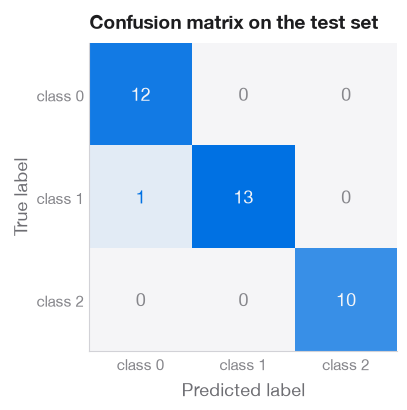

In [25]:
assert test_acc is not None, "Fill in the cell above"
print(f"chosen model: {grid.best_params_}")
print(f"5-fold CV accuracy on train+val: {grid.best_score_:.3f}")
print(f"test accuracy (36 wines):        {test_acc:.3f}")

fig, ax = plt.subplots(figsize=(4.5, 4))
cm_display = ConfusionMatrixDisplay.from_estimator(
    final_model,
    X_test,
    y_test,
    display_labels=["class 0", "class 1", "class 2"],
    cmap=BLUES,
    colorbar=False,
    ax=ax,
)
for text in cm_display.text_.ravel():  # gray zeros, so the diagonal and the mistakes stand out
    if text.get_text() == "0":
        text.set_color(INK3)
ax.set_title("Confusion matrix on the test set")
plt.show()

Rows are true classes, columns are predictions, and off-diagonal cells are mistakes. The test score is close to the CV score, so the model selection was honest. A much lower test score would point to leakage, overfitting to validation, or a shift between old and new data. In any case, report the test number as it is and do not tune on it.

## 7. Experiment log

After a dozen experiments nobody remembers which `k`, scaler and code version gave 0.97. Log every run: parameters, metrics, the seed and the git commit hash. The simplest tracker is a CSV file with one row per run.

In [26]:
RUNS_PATH = Path("runs.csv")  # a scratch file next to the notebook, do not commit it
RUNS_PATH.unlink(missing_ok=True)  # start a fresh log for this seminar


def get_git_commit():
    """Short hash of the current git commit, or 'no-git' outside a repository (e.g. Colab)."""
    try:
        result = subprocess.run(
            ["git", "rev-parse", "--short", "HEAD"], capture_output=True, text=True, check=True
        )
    except (OSError, subprocess.CalledProcessError):
        return "no-git"
    return result.stdout.strip()


print("git commit:", get_git_commit())

git commit: no-git


**Exercise 7.1.** Fix `log_run` so that it adds a row and keeps the rows already in the log.

In [27]:
def log_run(params, metrics, path=RUNS_PATH):
    """Append one run (time, git commit, seed, params, metrics) as a row of a CSV log."""
    row = {
        "time": datetime.now(timezone.utc).isoformat(timespec="seconds"),
        "git_commit": get_git_commit(),
        "seed": SEED,
        **params,
        **metrics,
    }
    runs = pd.read_csv(path).to_dict("records") if path.exists() else []
    pd.DataFrame(runs + [row]).to_csv(path, index=False)

Log a few experiments: both preprocessing options and several values of `k`.

In [28]:
for scaler_name in ["none", "standard"]:
    for k in [1, 3, 5, 9, 15, 29]:
        scaler = StandardScaler() if scaler_name == "standard" else "passthrough"
        model = Pipeline([("scaler", scaler), ("knn", KNeighborsClassifier(n_neighbors=k))])
        val_acc = model.fit(X_train, y_train).score(X_val, y_val)
        cv_acc = cross_val_score(model, X_trval, y_trval, cv=cv).mean()
        log_run(
            {"model": "knn", "scaler": scaler_name, "k": k},
            {"val_acc": round(val_acc, 4), "cv_acc": round(cv_acc, 4)},
        )
log_run({"model": "dummy", "scaler": "none", "k": None}, {"val_acc": round(dummy_val_acc, 4)})

runs = pd.read_csv(RUNS_PATH).astype({"k": "Int64"})  # Int64: integers with missing values
assert len(runs) == 13, "log_run must append rows, not overwrite the file (Exercise 7.1)"
print(f"{len(runs)} runs logged in {RUNS_PATH}")
runs.sort_values(["val_acc", "cv_acc"], ascending=False).head(8)

13 runs logged in runs.csv


,time,git_commit,seed,model,scaler,k,val_acc,cv_acc
11,2026-11-08T23:29:09+00:00,no-git,42,knn,standard,29,1.0000,0.9788
10,2026-11-08T23:29:09+00:00,no-git,42,knn,standard,15,1.0000,0.9579
9,2026-11-08T23:29:09+00:00,no-git,42,knn,standard,9,1.0000,0.9507
8,2026-11-08T23:29:09+00:00,no-git,42,knn,standard,5,0.9722,0.9507
7,2026-11-08T23:29:09+00:00,no-git,42,knn,standard,3,0.9722,0.9369
6,2026-11-08T23:29:09+00:00,no-git,42,knn,standard,1,0.9444,0.9227
0,2026-11-08T23:29:09+00:00,no-git,42,knn,none,1,0.7222,0.7542
1,2026-11-08T23:29:09+00:00,no-git,42,knn,none,3,0.7222,0.6978


With 36 validation objects, sorting by validation accuracy gives ties at the top, so we also log the CV score. The `git_commit` column shows which code version produced each row. Outside a git repository, for example in Colab, it says `no-git`.

### The same in MLflow

Real projects use a tracker such as [MLflow](https://mlflow.org/) or [Weights & Biases](https://wandb.ai/). It does what `log_run` does and adds a web UI to sort, filter and plot runs:

```python
import mlflow

mlflow.set_experiment("wine-knn")
with mlflow.start_run(run_name="knn-scaled-k5"):
    mlflow.log_params({"scaler": "standard", "k": 5, "seed": SEED})
    mlflow.log_metrics({"val_acc": val_acc, "cv_acc": cv_acc})
    mlflow.set_tag("git_commit", get_git_commit())
```

Then `mlflow ui` in a terminal shows the runs in the browser. The next cell runs this if MLflow is installed (`pip install mlflow`), with a throwaway local store, and skips it otherwise.

In [29]:
try:
    import mlflow
except ImportError:
    mlflow = None
    print("MLflow is not installed, skipping this cell (pip install mlflow to try it).")

if mlflow is not None:
    import tempfile

    tracking_dir = Path(tempfile.mkdtemp(prefix="mlflow_"))
    mlflow.set_tracking_uri(f"sqlite:///{tracking_dir / 'mlflow.db'}")
    mlflow.set_experiment("ymls-week01-wine-knn")
    for k in [1, 5, 15]:
        model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
        val_acc = model.fit(X_train, y_train).score(X_val, y_val)
        with mlflow.start_run(run_name=f"knn-scaled-k{k}"):
            mlflow.log_params({"scaler": "standard", "k": k, "seed": SEED})
            mlflow.log_metrics({"val_acc": val_acc})
            mlflow.set_tag("git_commit", get_git_commit())
    print(mlflow.search_runs()[["tags.mlflow.runName", "params.k", "metrics.val_acc"]])
    print(
        f"runs stored in {tracking_dir}; view them with: mlflow ui --backend-store-uri "
        f"sqlite:///{tracking_dir / 'mlflow.db'}"
    )

MLflow is not installed, skipping this cell (pip install mlflow to try it).


To make a run reproducible, fix every seed (`random_state=SEED` in splits and models, `np.random.default_rng(SEED)` for your own randomness), record the git commit and the library versions, and never edit raw data in place: save a new version instead. Then anyone, including you a month later, can rerun the experiment and get the same numbers.

## 8. Summary

- Name things in code: objects, features, the design matrix $X$ of shape $\ell \times d$, the target $y$, the model $a(x)$, the metric.
- Split first. Train fits, validation (or cross-validation) chooses, test reports once.
- Start with baselines. Here a constant gets about 0.4 and a one-feature rule about 0.75, and kNN on raw features does not beat that rule.
- Scale features for distance-based models, inside a `Pipeline` so that the scaler sees only training data.
- Choose hyperparameters by cross-validation. On small data, differences within one standard deviation are noise.
- Leakage makes results look better than they are. The worst cases are preprocessing that uses labels outside CV, and copies of one object on both sides of a split.
- Log every run with its parameters, metrics, seed and git commit.

Next: `week0_01_02_knn_practice.ipynb` (decision boundaries, metrics, the curse of dimensionality) and HW1 (kNN from scratch).